# Experiment: Weather-Based Activity Prediction Using Decision Trees
**Topic:** Decision Tree Classification (Decision Stump)  
**Algorithm:** CART with Gini Impurity & Information Gain  
**Objective:** Predict whether an individual will engage in outdoor activity (**Go Out**) or remain indoors (**Stay In**) based on categorical weather observations (**Sunny** vs. **Rainy**).

---

## 1. Problem Statement & Mathematical Formulation

In categorical decision tree modeling, features are discrete states. When a tree is constrained to depth 1 (a *decision stump*), it functions as a primary rule extractor that isolates the single most informative feature split.

### Mathematical Impurity Metrics

#### 1. Gini Impurity
$$\text{Gini}(D) = 1 - \sum_{k=1}^{K} p_k^2$$
where $p_k$ is the relative frequency of class $k$ in dataset $D$.

#### 2. Entropy & Information Gain
$$\text{Entropy}(D) = - \sum_{k=1}^{K} p_k \log_2(p_k)$$
$$\text{Gain}(D, A) = \text{Entropy}(D) - \sum_{v \in \text{Values}(A)} \frac{|D_v|}{|D|} \text{Entropy}(D_v)$$
A feature split that maximizes Information Gain minimizes the conditional entropy of the resulting partitions.


In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Construction & Contingency Table

The dataset captures observational weather data and the corresponding binary decision:
- **Weather**: Categorical predictor (`Sunny`, `Rainy`).
- **Activity / Go_Out**: Binary target (`Go Out`, `Stay In`).


In [2]:
# Construct experimental observations
data = pd.DataFrame({
    'Weather': ['Sunny', 'Sunny', 'Sunny', 'Rainy', 'Rainy', 'Rainy', 'Sunny', 'Rainy'],
    'Go_Out': ['Go Out', 'Go Out', 'Go Out', 'Stay In', 'Stay In', 'Stay In', 'Go Out', 'Stay In']
})

print("Dataset Overview:")
display(data)

# Contingency Cross-Tabulation
contingency = pd.crosstab(data['Weather'], data['Go_Out'], margins=True)
print("\nContingency Table (Weather vs. Activity Decision):")
display(contingency)


Dataset Overview:


,Weather,Go_Out
0,Sunny,Go Out
1,Sunny,Go Out
2,Sunny,Go Out
3,Rainy,Stay In
4,Rainy,Stay In
5,Rainy,Stay In
6,Sunny,Go Out
7,Rainy,Stay In



Contingency Table (Weather vs. Activity Decision):


Go_Out,Go Out,Stay In,All
Weather,,,
Rainy,0,4,4
Sunny,4,0,4
All,4,4,8


### Class Distribution by Weather Category
Visualizing the cross-tabulated frequency confirms complete linear/deterministic separability between weather condition and activity decision.


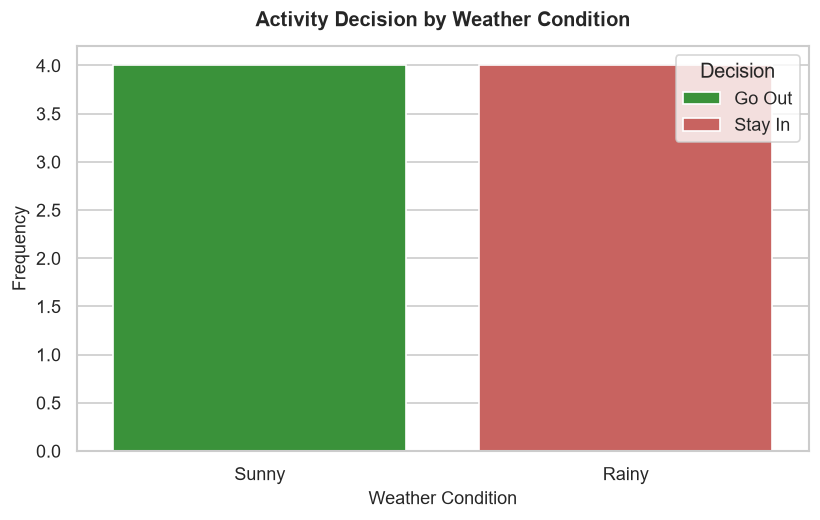

In [3]:
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(
    data=data,
    x='Weather',
    hue='Go_Out',
    palette={'Go Out': '#2ca02c', 'Stay In': '#d9534f'}
)
plt.title("Activity Decision by Weather Condition", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Weather Condition", fontsize=11)
plt.ylabel("Frequency", fontsize=11)
plt.legend(title="Decision")
plt.tight_layout()
plt.show()


## 3. Categorical Encoding & Model Training

We map the discrete feature `Weather` to numeric codes (`Sunny = 0`, `Rainy = 1`) and train a `DecisionTreeClassifier` with `max_depth=1`.


In [4]:
# Numeric feature mapping
encoder = {'Sunny': 0, 'Rainy': 1}
data['Weather_Code'] = data['Weather'].map(encoder)

X = data[['Weather_Code']]
y = data['Go_Out']

# Fit Decision Stump (depth=1)
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=1,
    random_state=42
)
model.fit(X, y)

print("Decision Tree Classifier trained successfully.")
print(f"Split Threshold: {model.tree_.threshold[0]:.2f}")
print(f"Impurity at Root: {model.tree_.impurity[0]:.4f}")


Decision Tree Classifier trained successfully.
Split Threshold: 0.50
Impurity at Root: 0.5000


## 4. Visualizing the Decision Tree Structure

The graphical tree displays the decision node, Gini impurity, sample count, and resulting leaf predictions.


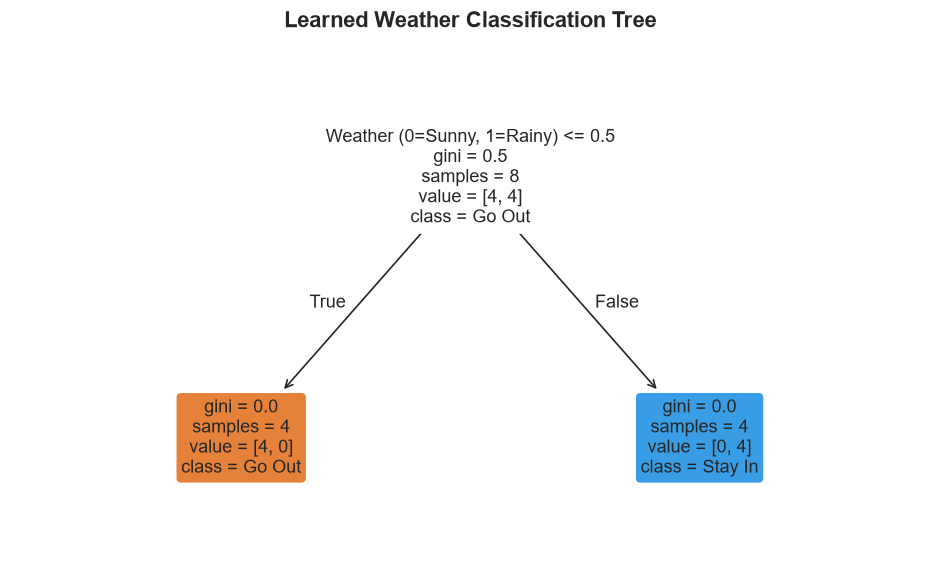

Extracted Decision Rules:

|--- Weather_Code <= 0.50
|   |--- class: Go Out
|--- Weather_Code >  0.50
|   |--- class: Stay In



In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_tree(
    model,
    feature_names=['Weather (0=Sunny, 1=Rainy)'],
    class_names=model.classes_,
    filled=True,
    rounded=True,
    impurity=True,
    ax=ax,
    fontsize=11
)
plt.title("Learned Weather Classification Tree", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("Extracted Decision Rules:\n")
print(export_text(model, feature_names=['Weather_Code']))


## 5. Model Evaluation & Confusion Matrix

We evaluate classification performance across the observational sample.


Classification Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

      Go Out       1.00      1.00      1.00         4
     Stay In       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



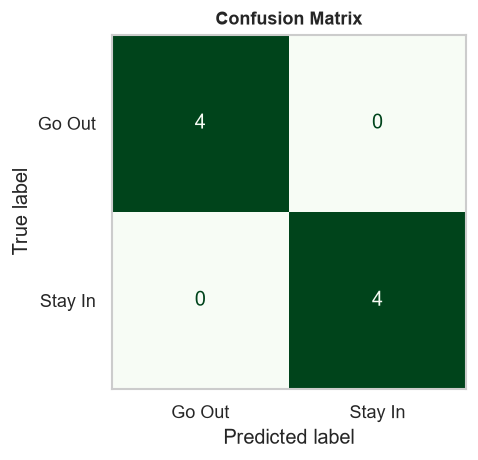

In [6]:
y_pred = model.predict(X)
acc = accuracy_score(y, y_pred)
print(f"Classification Accuracy: {acc * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y, y_pred))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y,
    y_pred,
    display_labels=model.classes_,
    cmap='Greens',
    ax=ax,
    colorbar=False
)
plt.title("Confusion Matrix", fontsize=11, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()


## 6. Inference on Novel Forecasts

We verify deterministic predictions for prospective weather conditions.


In [7]:
test_scenarios = pd.DataFrame({
    'Weather': ['Sunny', 'Rainy'],
    'Weather_Code': [0, 1]
})

test_scenarios['Predicted_Decision'] = model.predict(test_scenarios[['Weather_Code']])
probabilities = model.predict_proba(test_scenarios[['Weather_Code']])

for idx, row in test_scenarios.iterrows():
    p_go = probabilities[idx, list(model.classes_).index('Go Out')]
    p_stay = probabilities[idx, list(model.classes_).index('Stay In')]
    print(f"Condition: {row['Weather']:<6} -> Prediction: {row['Predicted_Decision']:<8} "
          f"[P(Go Out)={p_go:.2f}, P(Stay In)={p_stay:.2f}]")


Condition: Sunny  -> Prediction: Go Out   [P(Go Out)=1.00, P(Stay In)=0.00]
Condition: Rainy  -> Prediction: Stay In  [P(Go Out)=0.00, P(Stay In)=1.00]


## 7. Observations & Conclusion

1. **Deterministic Separation:** The weather feature partitions the target space with zero residual impurity (leaf Gini $= 0.0$ on both branches).
2. **Optimal Decision Stump:** A single split (`Weather_Code <= 0.5`) achieves 100% classification accuracy, proving that additional tree depth is unnecessary.
3. **Formal Decision Rules:**
   - $\text{Weather} = \text{Sunny} \implies \text{Go Out}$ (Probability = 1.0)
   - $\text{Weather} = \text{Rainy} \implies \text{Stay In}$ (Probability = 1.0)
